# Flight Delay Prediction: Evaluation and Calibration

Balanced Logistic Regression and frozen tuned XGBoost. All model/calibration/threshold decisions use validation; final test evaluation is a separate frozen stage. This notebook reads genuine saved outputs and never retrains or reselects automatically.

In [1]:
from pathlib import Path
import sys
import json
import pandas as pd
from IPython.display import display, Image
ROOT = next(
    (path for path in (Path.cwd(), *Path.cwd().parents) if (path / 'pyproject.toml').is_file()),
    None,
)
if ROOT is None:
    raise FileNotFoundError('Run this notebook from within the flight-delay repository')
if str(ROOT / 'src') not in sys.path:
    sys.path.insert(0, str(ROOT / 'src'))
from flight_delay.evaluation.metrics import evaluate, align_predictions
from flight_delay.evaluation.calibration import reliability
ROOT = Path.cwd()
if ROOT.name == 'notebooks': ROOT = ROOT.parent
OUT = ROOT / 'reports/evaluation'
def read(name):
    path = OUT / name
    if not path.exists():
        raise FileNotFoundError(f'{path}: run the validation stage documented below first')
    return json.loads(path.read_text())
selection = read('selection.json')
canonical = json.loads((ROOT / 'docs/canonical_evaluation.json').read_text())

## Objective and chronological methodology
Predict arrival delay ≥15 minutes before departure. Preserve original train/validation/test dates. Refit bases on the first 80% of training dates; fit sigmoid and isotonic maps on the remaining 20%. Pick calibration by validation Brier, with log loss as tie-break. Recommend the validation F1 maximum; F2 and illustrative precision floors expose sensitivity. The frozen base is not refitted on all training records afterward.

In [2]:
display(pd.DataFrame(selection['windows']).T)
display(pd.DataFrame(selection['models']).T[['calibration','threshold']])
print('Validation winner by selected-probability AP:', selection['winner'])

,n,first,last
base_train,181405,2013-01-01,2013-07-23
train_calibration,46894,2013-07-24,2013-09-12
validation,50466,2013-09-13,2013-11-06


,calibration,threshold
logistic_balanced,isotonic,0.343573
xgboost_tuned_full,isotonic,0.25


Validation winner by selected-probability AP: logistic_balanced


## Class distribution and prior model comparison
Original full-training reference AP/ROC-AUC: LR 0.203867/0.601490, balanced LR 0.206047/0.604281, XGBoost 0.239206/0.629462. These are validation references, not test scores. Refitted early-training models below are distinct fitted estimators.

In [3]:
metrics = read('validation_metrics.json')
display(pd.DataFrame(metrics).T[['n','prevalence','average_precision','roc_auc','precision','recall','f1']])

,n,prevalence,average_precision,roc_auc,precision,recall,f1
logistic_balanced,50466,0.156402,0.223285,0.635976,0.223727,0.604713,0.326616
xgboost_tuned_full,50466,0.156402,0.212871,0.627927,0.216151,0.593437,0.316883


## ROC and Precision–Recall
Average Precision is the sum of precision weighted by increases in recall; it is not trapezoidal PR area. The horizontal PR baseline equals prevalence.

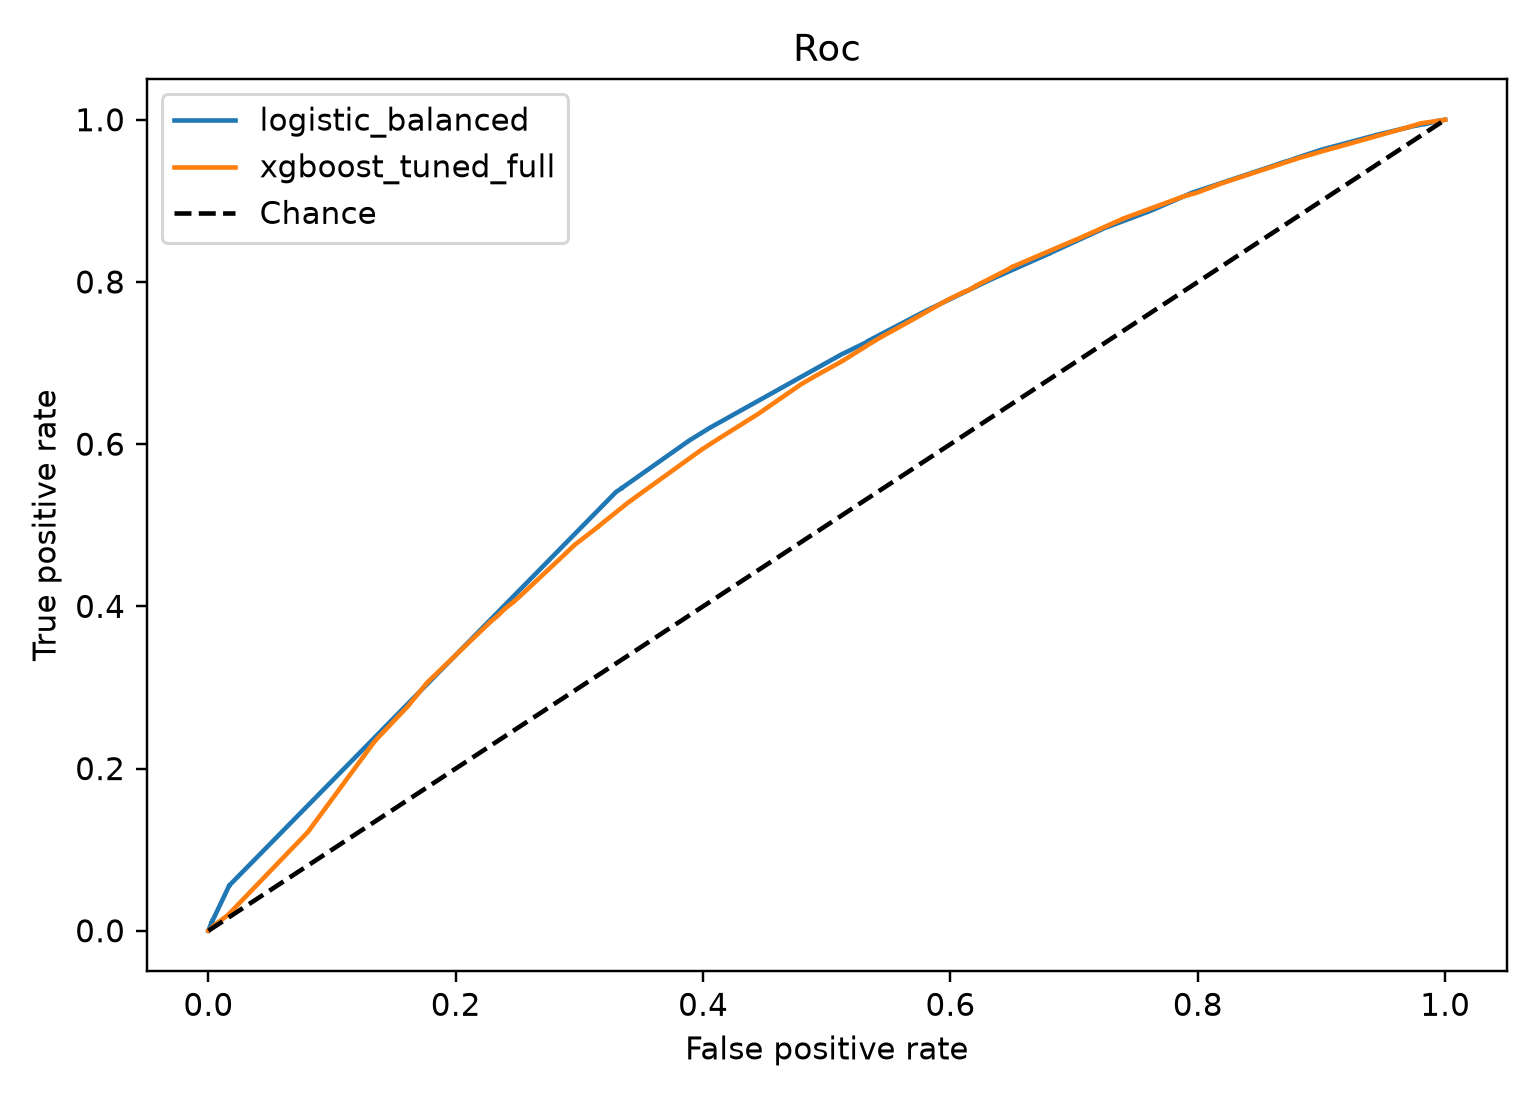

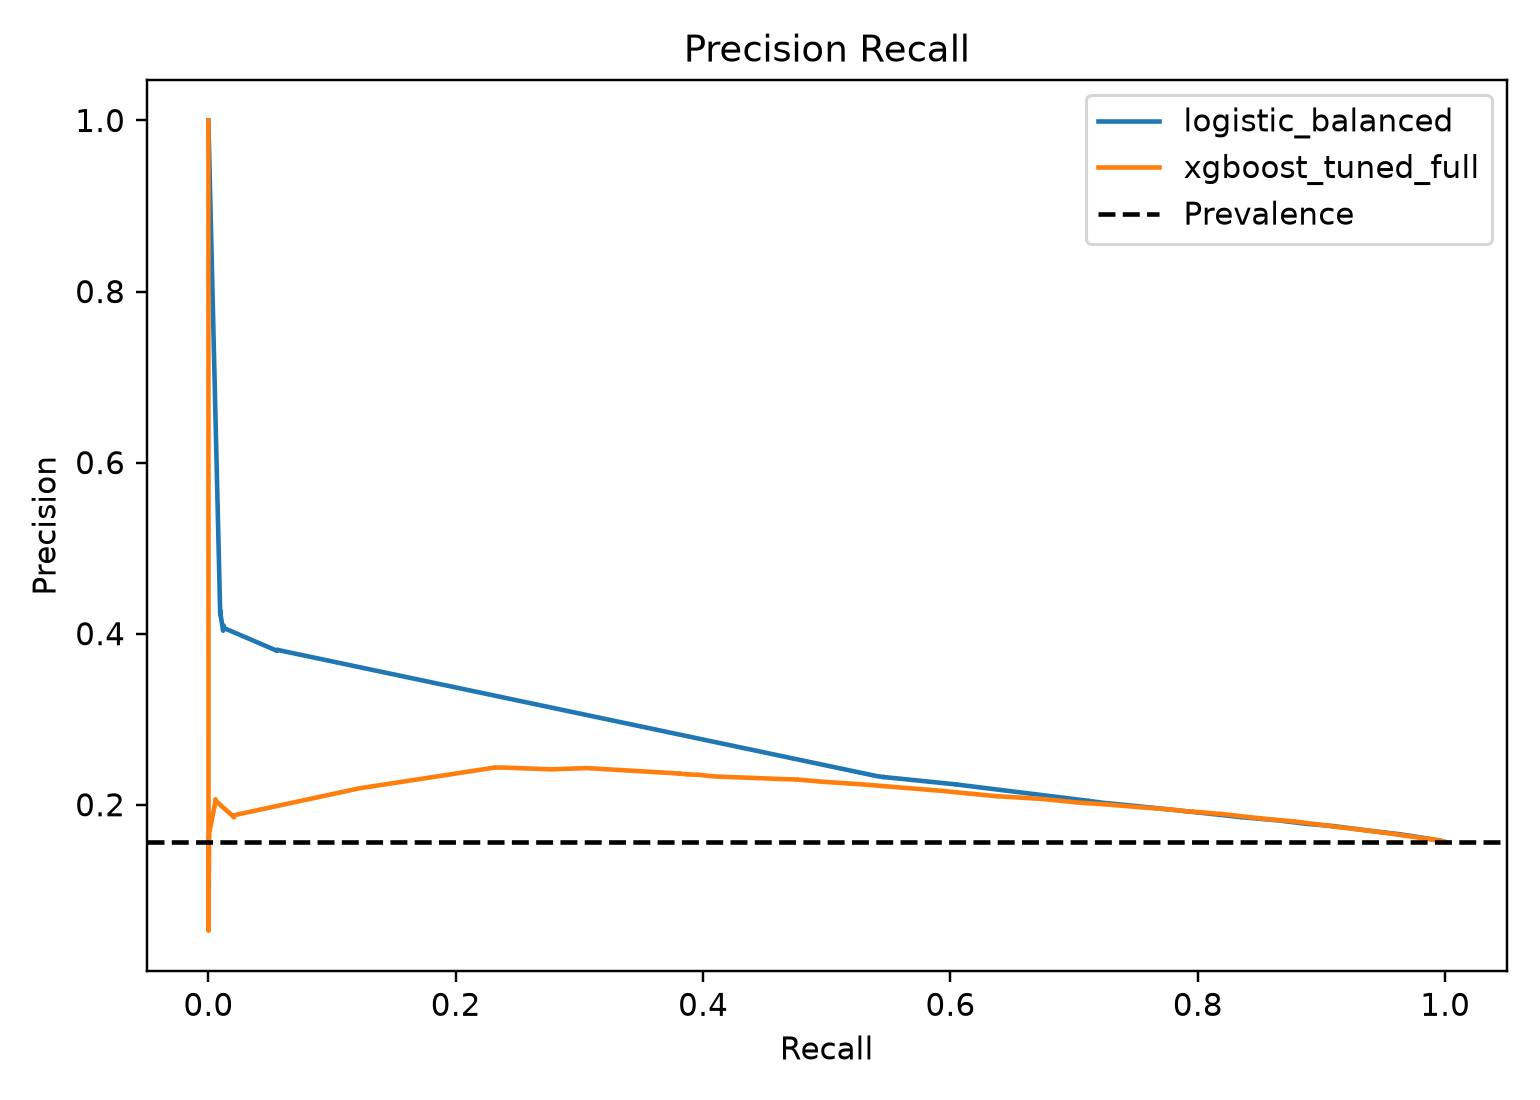

In [4]:
for name in ['roc','precision_recall']:
    display(Image(filename=str(OUT / 'figures/validation' / f'{name}.png')))

## Confusion matrices and class-wise performance

logistic_balanced


,precision,recall,f1-score,support
0,0.892901,0.610998,0.725528,42573.000000
1,0.223727,0.604713,0.326616,7893.000000
accuracy,0.610015,0.610015,0.610015,0.610015
macro avg,0.558314,0.607855,0.526072,50466.000000
weighted avg,0.788241,0.610015,0.663137,50466.000000


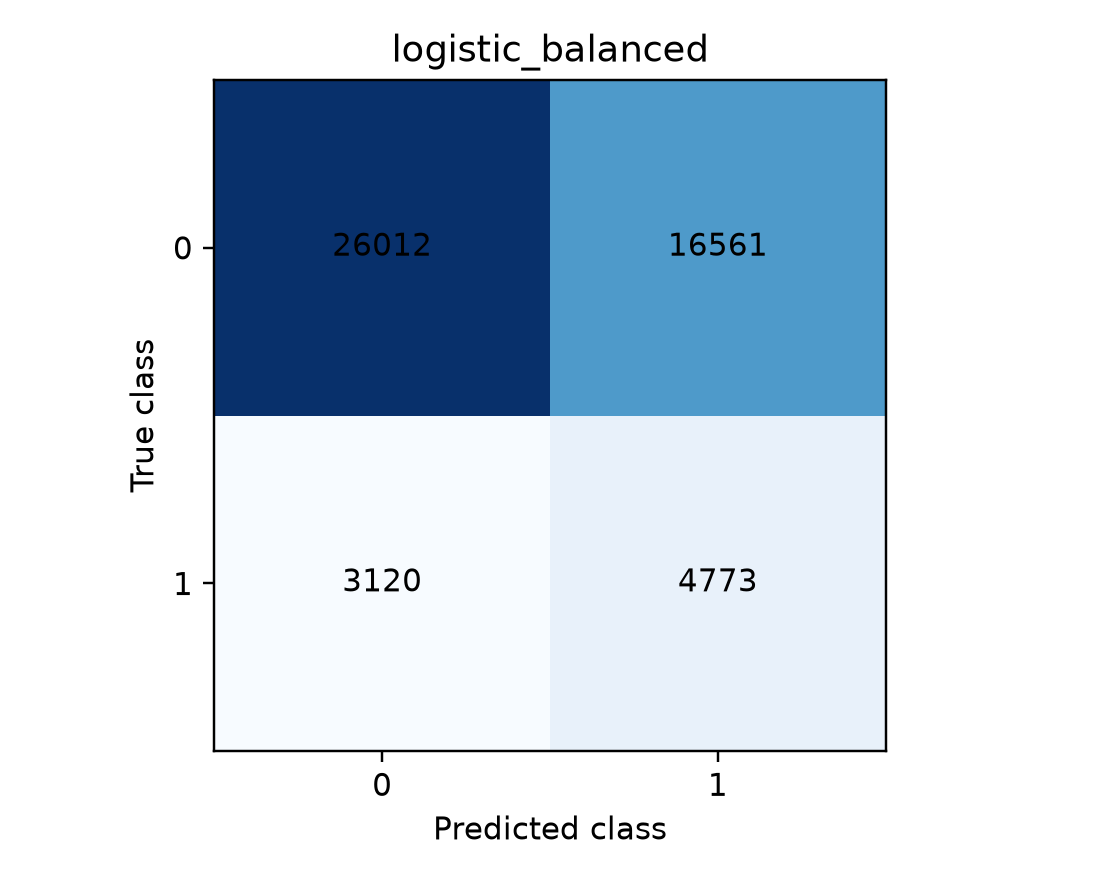

xgboost_tuned_full


,precision,recall,f1-score,support
0,0.888561,0.601015,0.717034,42573.00000
1,0.216151,0.593437,0.316883,7893.00000
accuracy,0.599830,0.599830,0.599830,0.59983
macro avg,0.552356,0.597226,0.516958,50466.00000
weighted avg,0.783394,0.599830,0.654449,50466.00000


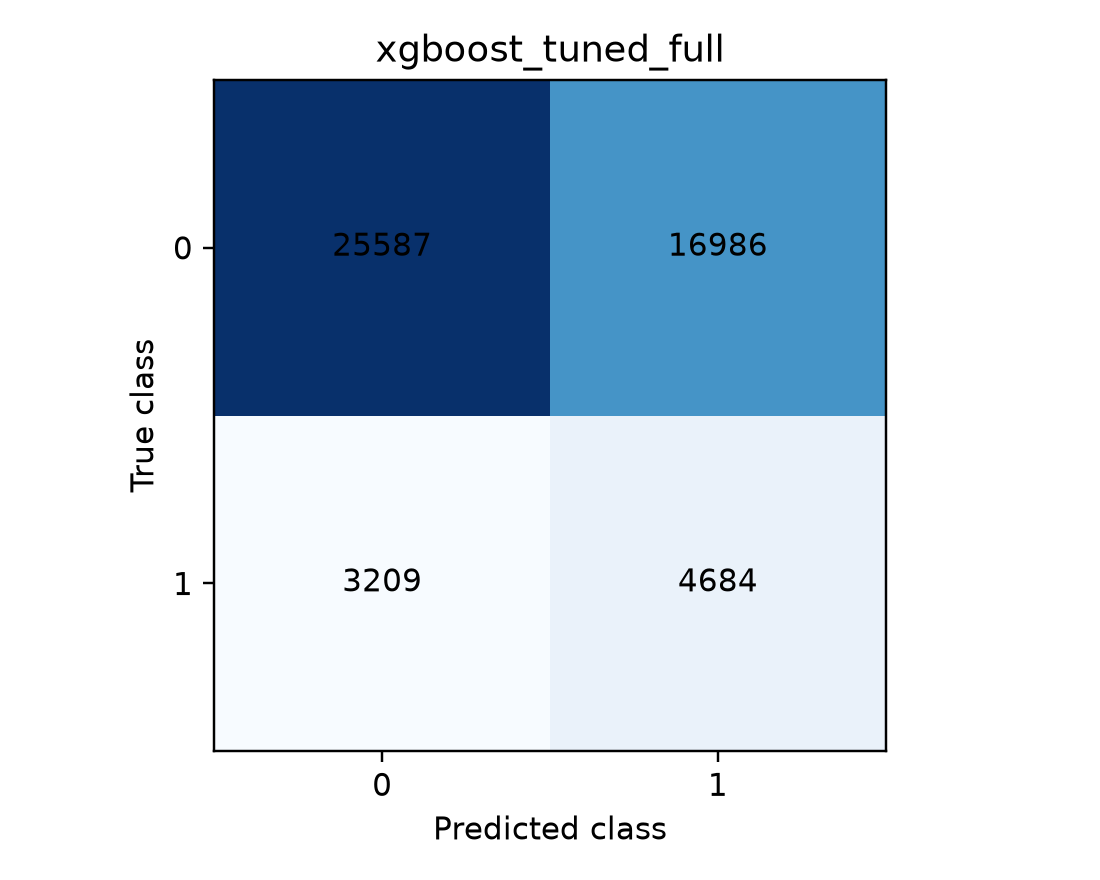

In [5]:
for name, result in metrics.items():
    print(name)
    display(pd.DataFrame(result['class_metrics']).T)
    display(Image(filename=str(OUT / 'figures/validation' / f'{name}_confusion.png')))

## Raw, sigmoid and isotonic calibration
Balanced training changes the probability scale. Sigmoid is an unpenalized-in-practice logistic map of clipped log odds (C=1e10); isotonic is a nonparametric monotone map. Ranking may change through isotonic ties. No calibrator is fitted on validation or test labels.

,brier,log_loss,mean_probability,prevalence,calibration_bias,roc_auc,average_precision
logistic_balanced_raw,0.521863,1.395895,0.781884,0.156402,0.625482,0.646651,0.253235
logistic_balanced_sigmoid,0.155823,0.492023,0.324285,0.156402,0.167882,0.646651,0.253235
logistic_balanced_isotonic,0.150899,0.482197,0.305147,0.156402,0.148745,0.635976,0.223285
xgboost_tuned_full_raw,0.305923,0.86001,0.540171,0.156402,0.383769,0.627764,0.211211
xgboost_tuned_full_sigmoid,0.138253,0.443644,0.233095,0.156402,0.076693,0.627764,0.211211
xgboost_tuned_full_isotonic,0.137199,0.442804,0.230979,0.156402,0.074576,0.627927,0.212871


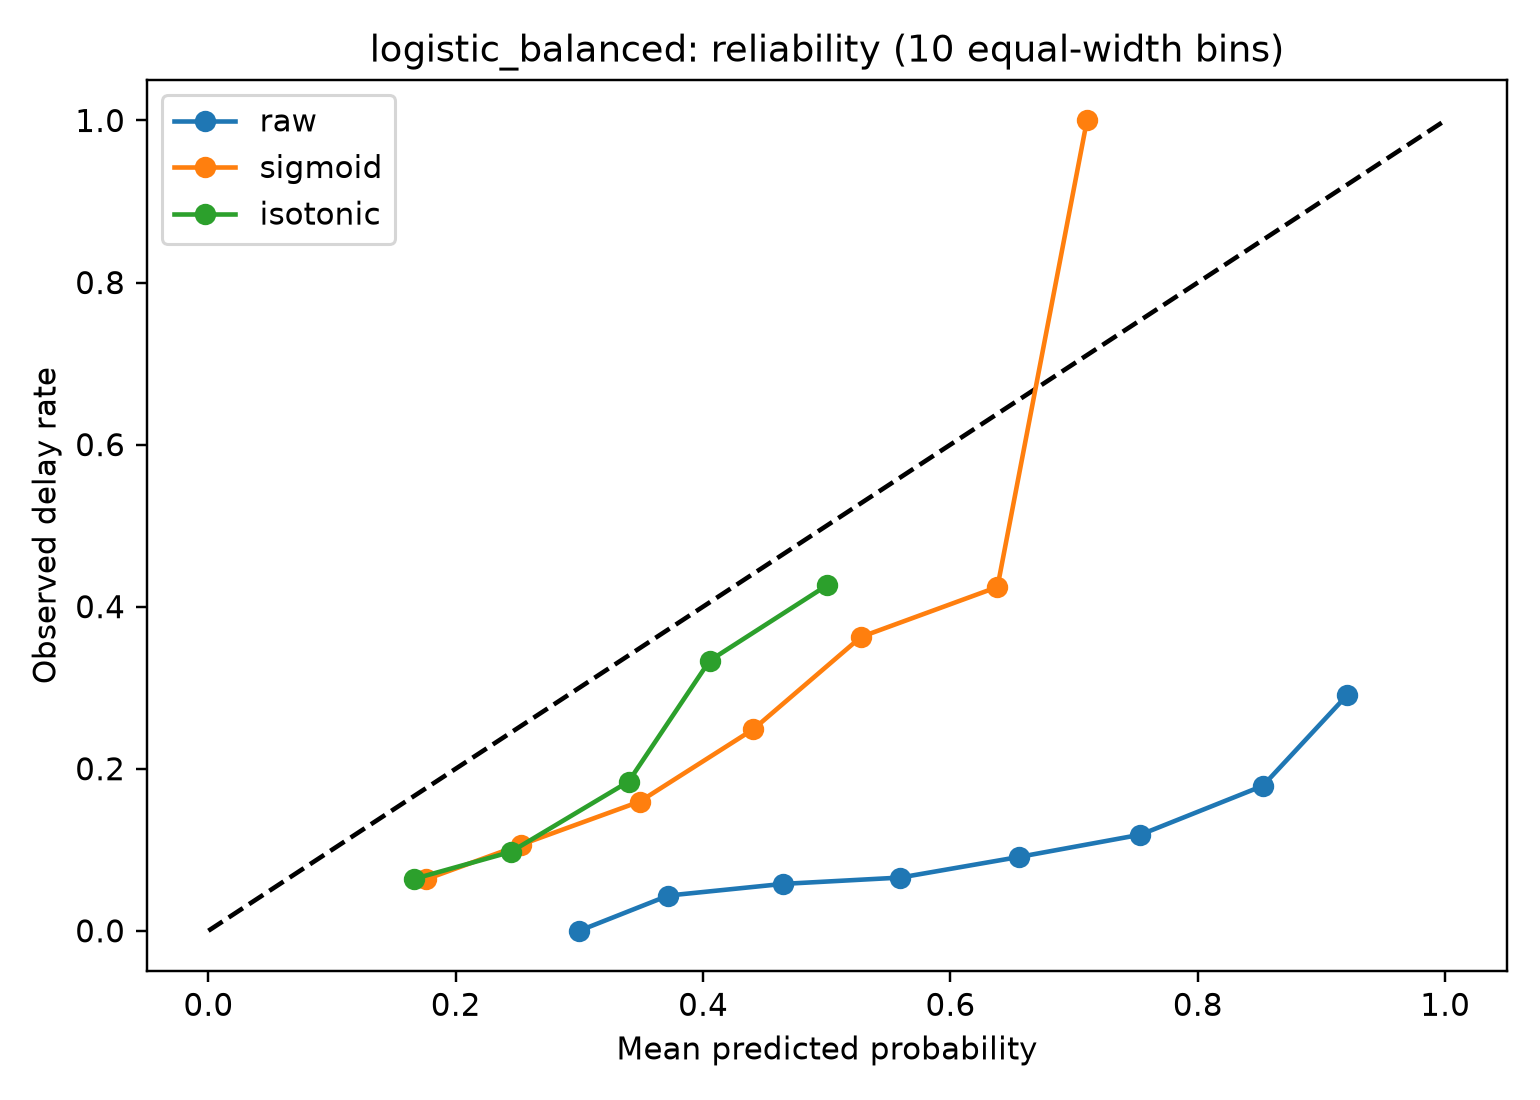

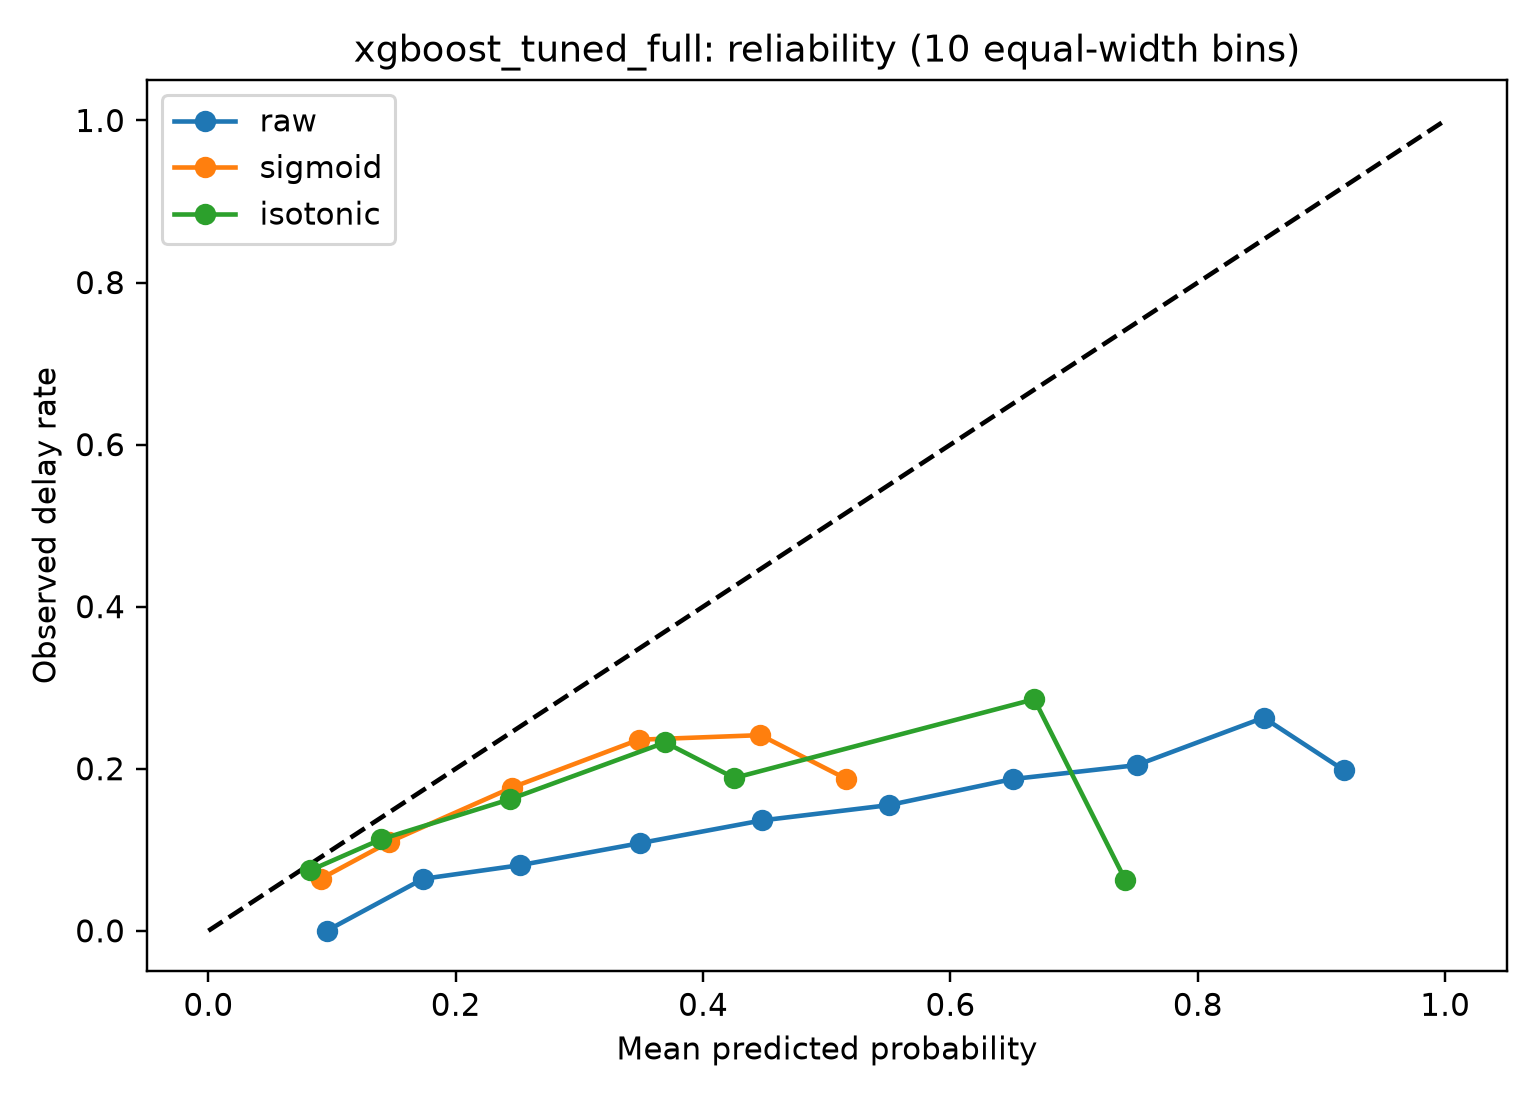

In [6]:
calibration = read('calibration_metrics.json')
display(pd.DataFrame(calibration).T[['brier','log_loss','mean_probability','prevalence','calibration_bias','roc_auc','average_precision']])
for name in selection['models']:
    display(Image(filename=str(OUT / 'figures/validation' / f'{name}_reliability.png')))

## Proper scoring rules
Lower Brier and log loss are better. Reliability uses ten equal-width bins, omits empty bins and exports bin counts alongside each plot. Calibration bias is mean probability minus prevalence.

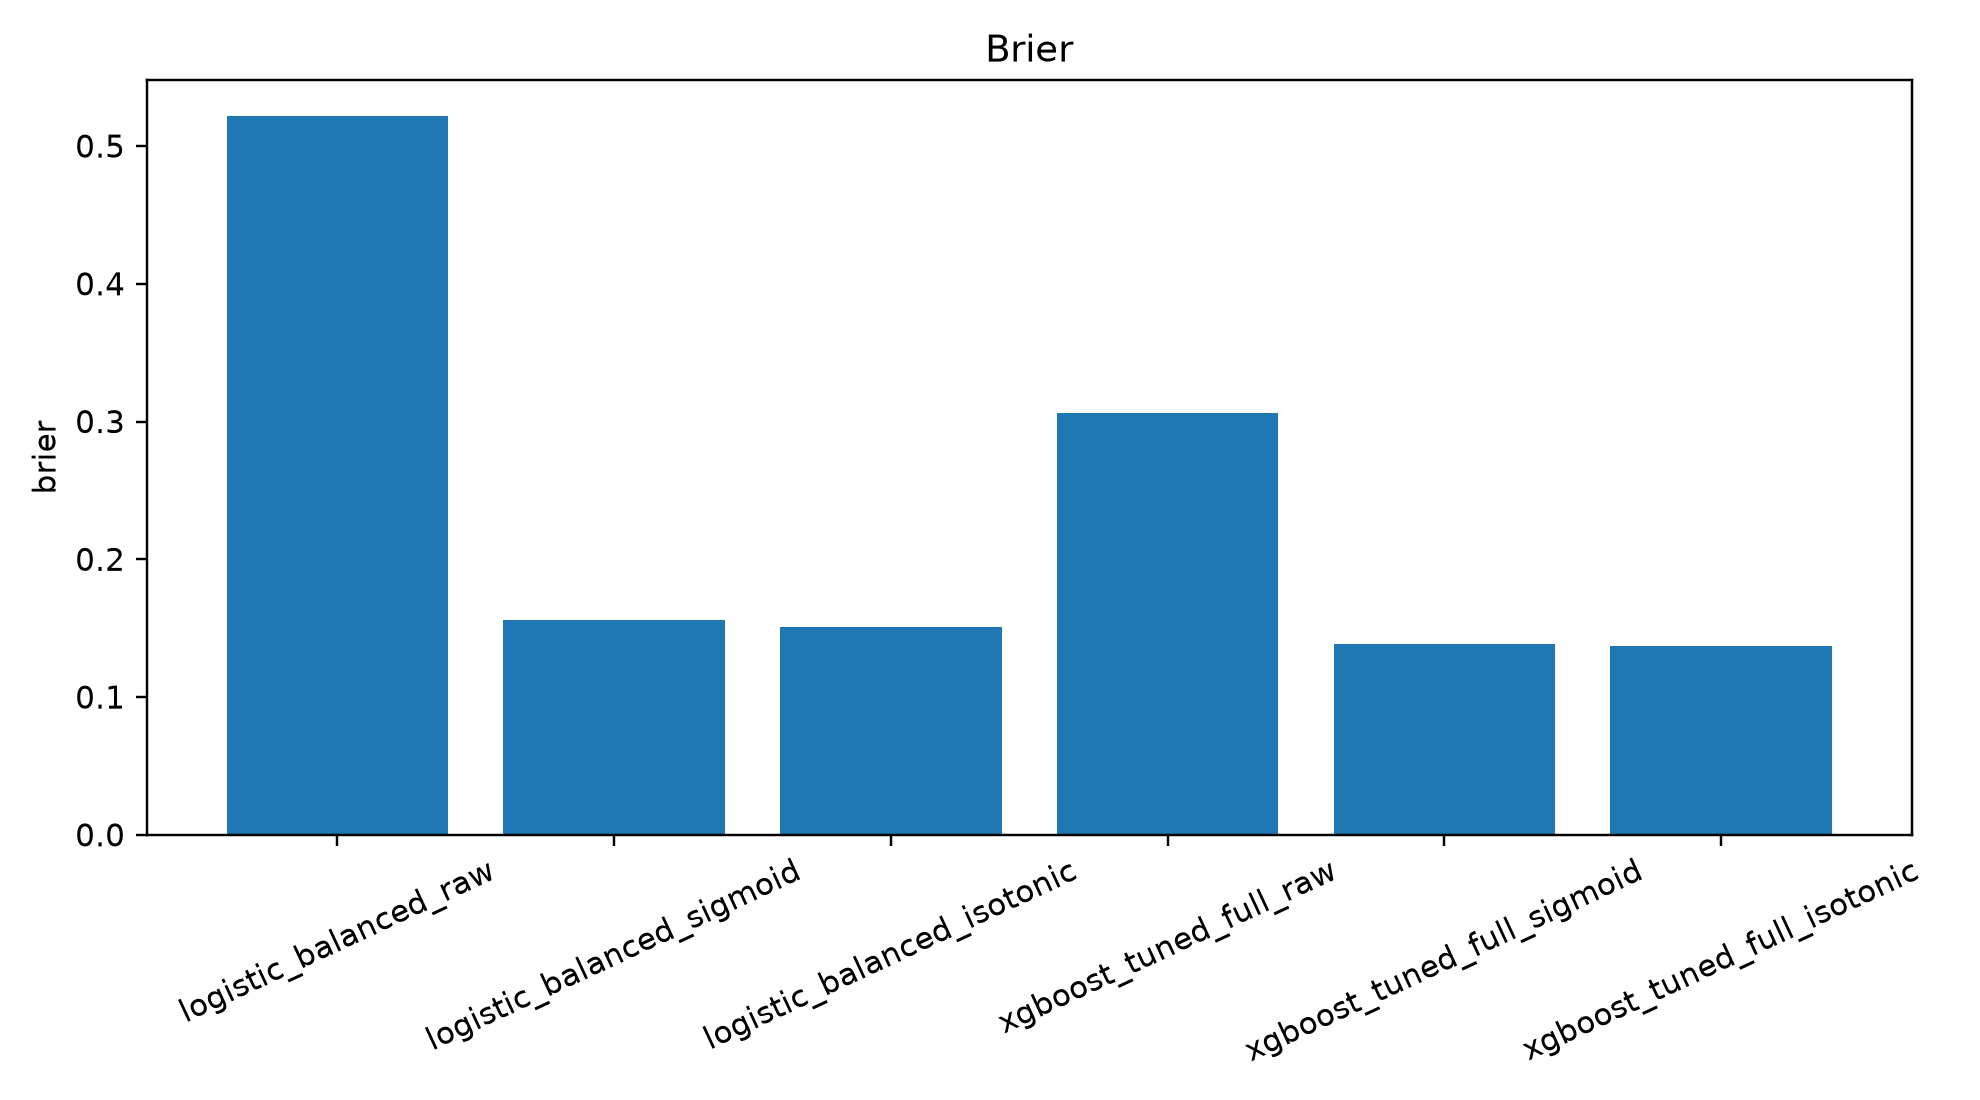

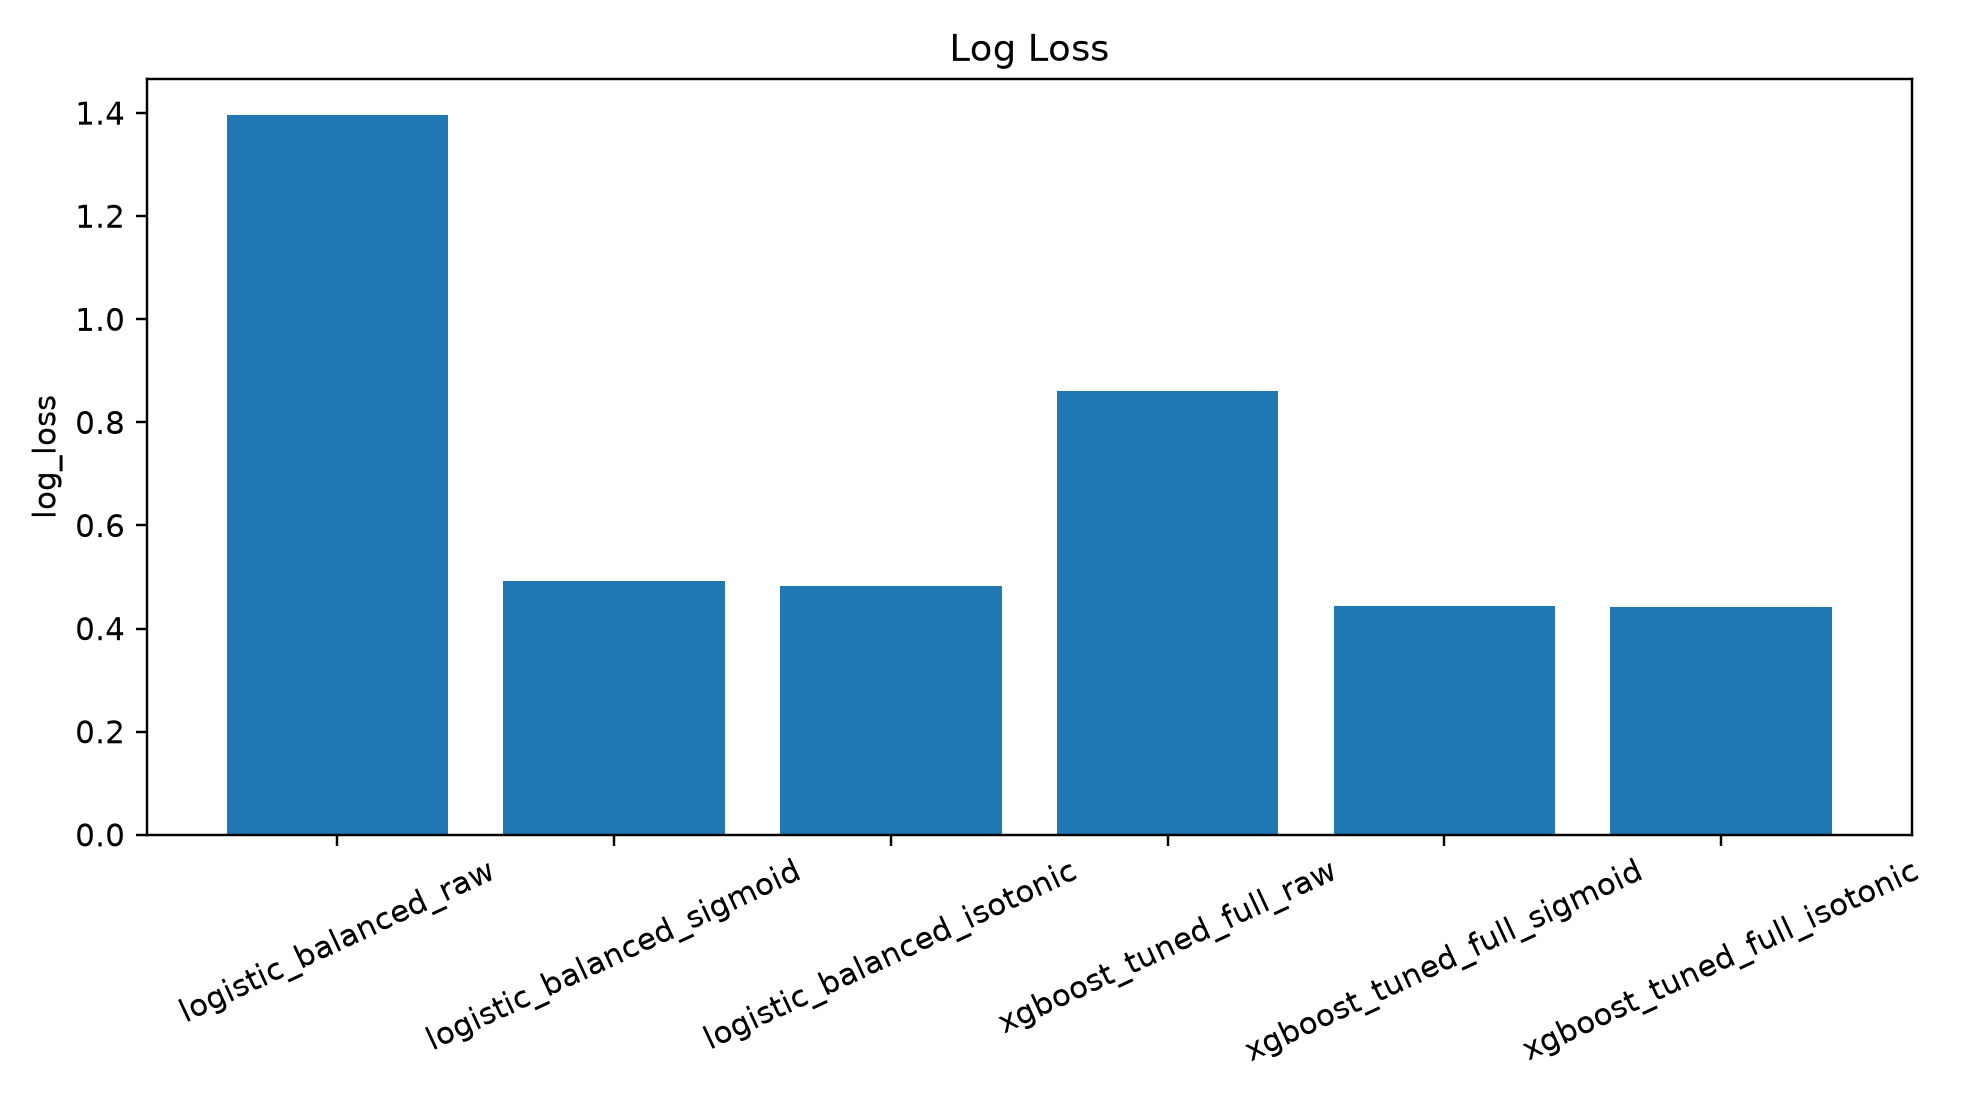

In [7]:
for name in ['brier','log_loss']:
    display(Image(filename=str(OUT / 'figures/calibration' / f'{name}.png')))

## Threshold analysis and operational tradeoffs
Default 0.5 can miss most delayed flights after probability calibration. F1 is a reproducible provisional objective, not an approved operational cost function. Precision floors of 0.20, 0.25, 0.30 and 0.40 are sensitivity assumptions only. No test result may change these choices.

logistic_balanced


,threshold,precision,recall,f1,f2,tp,fp,tn,fn,predicted_positive_rate,false_alarm_rate,missed_delay_rate
max_f1,0.343573,0.223727,0.604713,0.326616,0.451083,4773.0,16561.0,26012.0,3120.0,0.422740,0.389002,0.395287
max_f2,0.252551,0.174990,0.910047,0.293537,0.494561,7183.0,33865.0,8708.0,710.0,0.813379,0.795457,0.089953
reference_0.5,0.500000,0.426136,0.009502,0.018590,0.011812,75.0,101.0,42472.0,7818.0,0.003487,0.002372,0.990498


,threshold,precision,recall,f1,f2,tp,fp,tn,fn,predicted_positive_rate,false_alarm_rate,missed_delay_rate
0.2,0.318681,0.201793,0.727100,0.315911,0.478154,5739.0,22701.0,19872.0,2154.0,0.563548,0.533225,0.272900
0.25,0.358918,0.381076,0.055619,0.097070,0.067076,439.0,713.0,41860.0,7454.0,0.022827,0.016748,0.944381
0.3,0.358918,0.381076,0.055619,0.097070,0.067076,439.0,713.0,41860.0,7454.0,0.022827,0.016748,0.944381
0.4,0.369565,0.408333,0.012416,0.024099,0.015403,98.0,142.0,42431.0,7795.0,0.004756,0.003335,0.987584


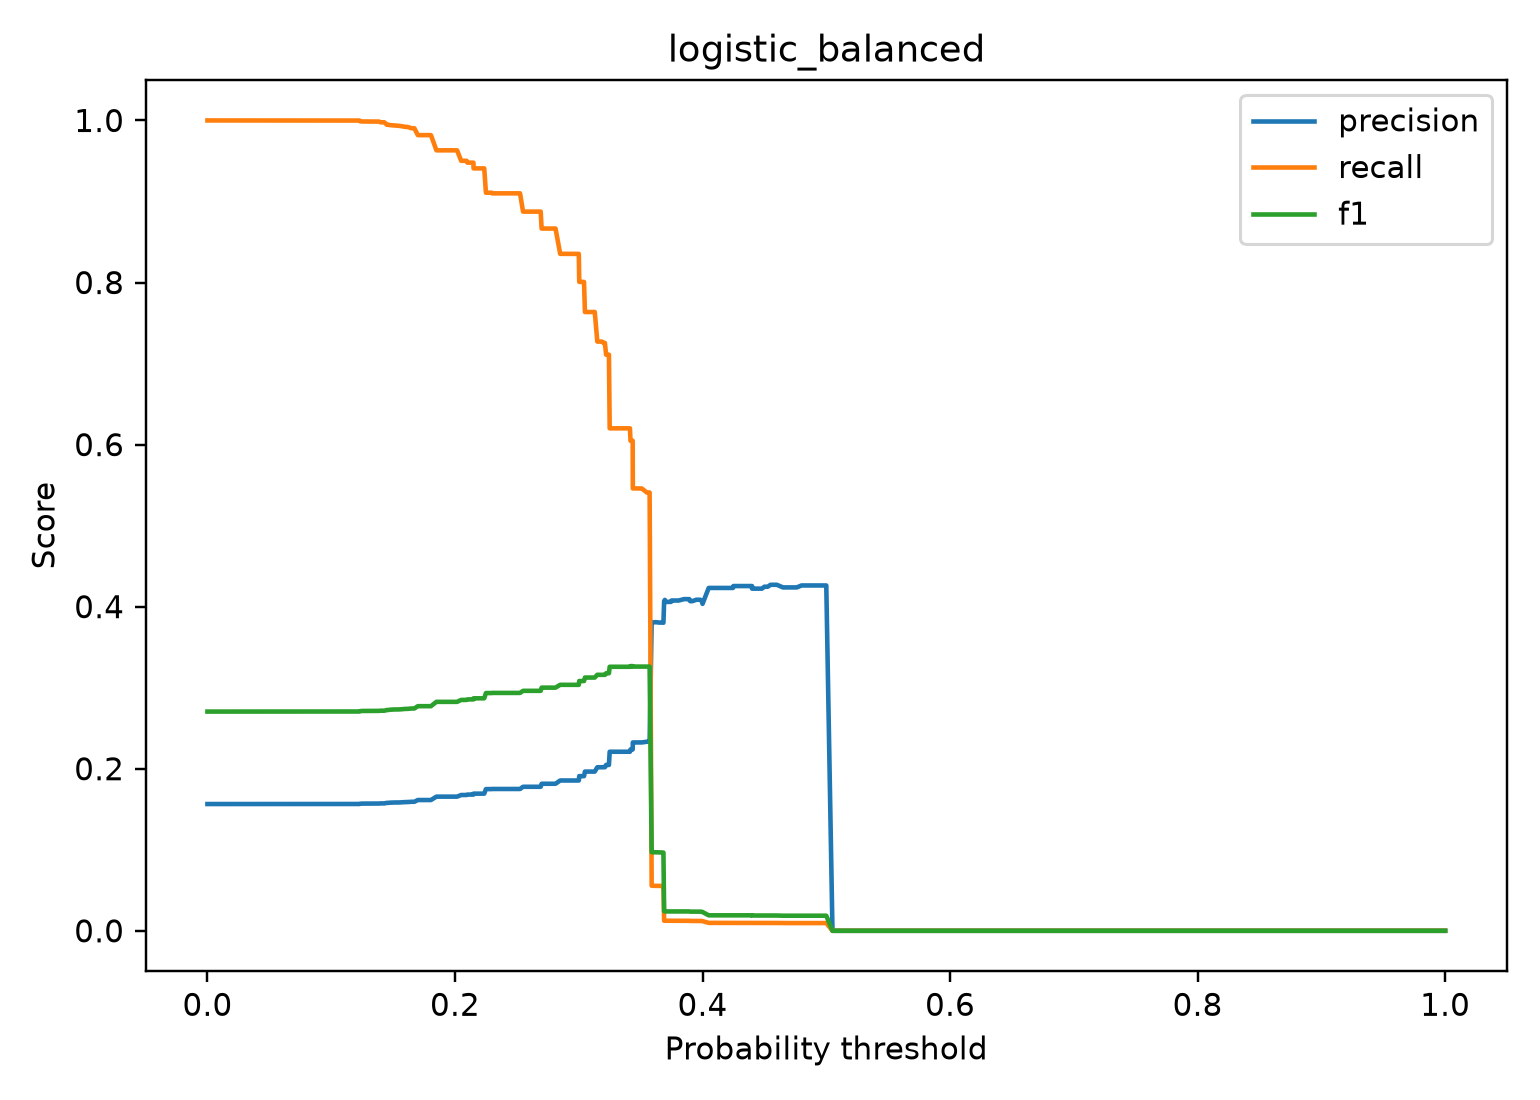

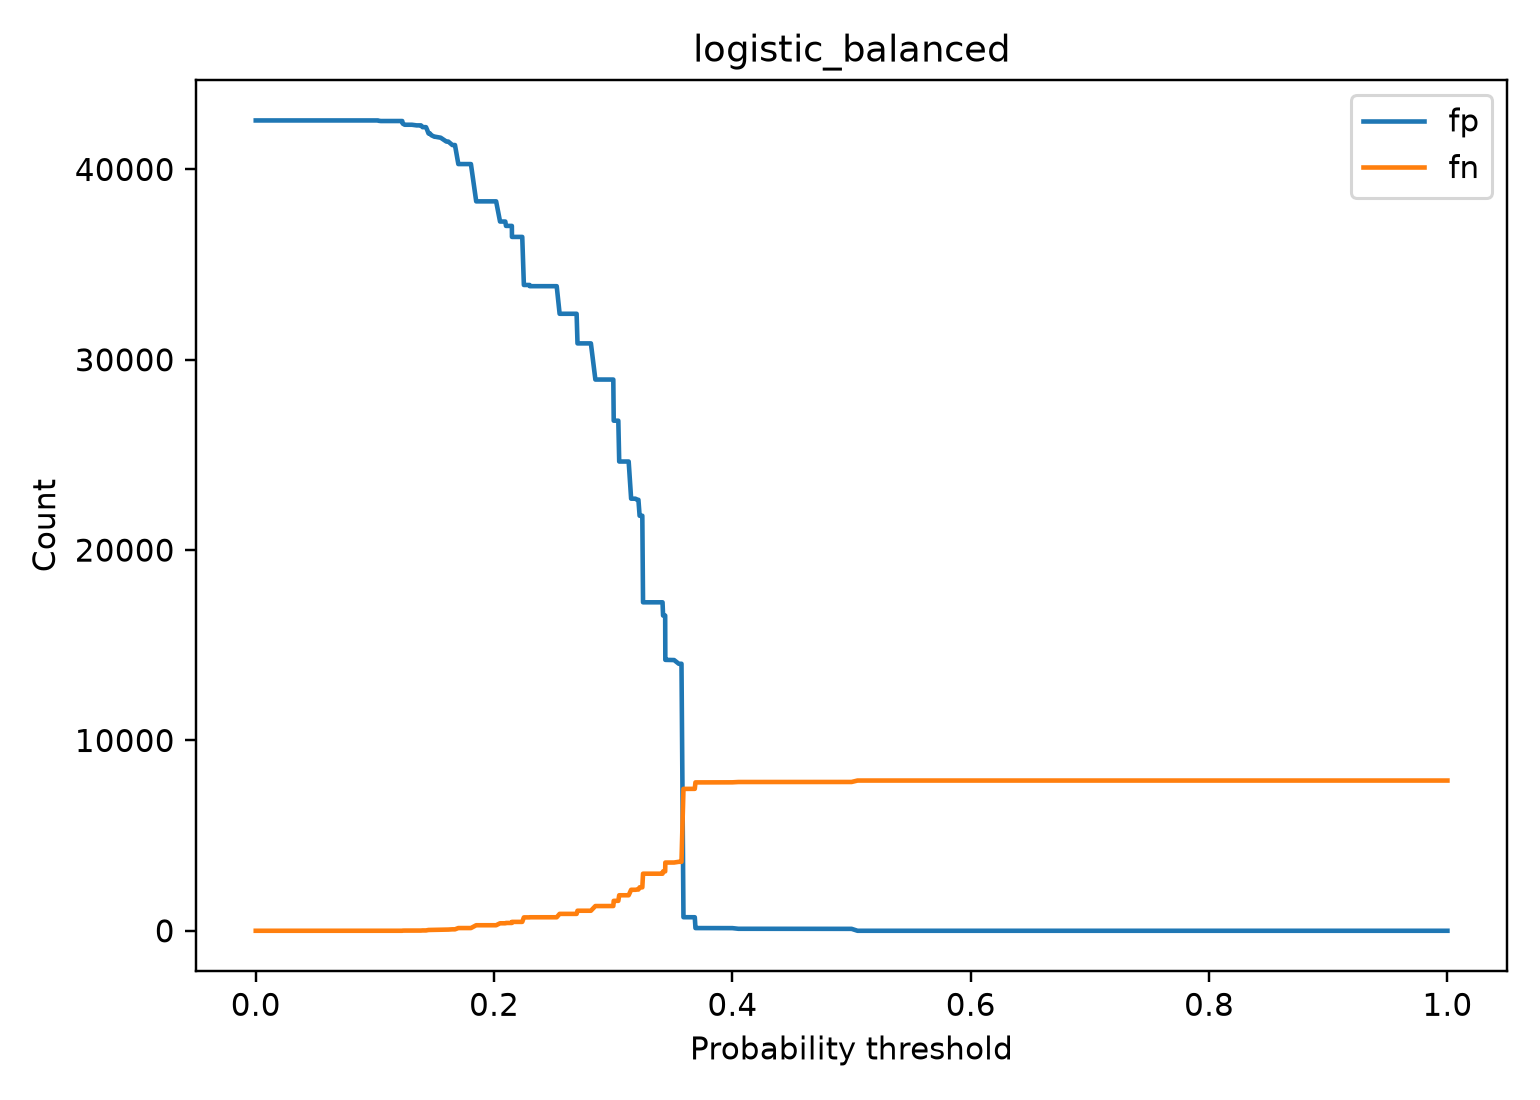

xgboost_tuned_full


,threshold,precision,recall,f1,f2,tp,fp,tn,fn,predicted_positive_rate,false_alarm_rate,missed_delay_rate
max_f1,0.250000,0.216151,0.593437,0.316883,0.439878,4684.0,16986.0,25587.0,3209.0,0.429398,0.398985,0.406563
max_f2,0.119565,0.180426,0.877993,0.299339,0.495134,6930.0,31479.0,11094.0,963.0,0.761087,0.739412,0.122007
reference_0.5,0.500000,0.166667,0.000633,0.001262,0.000791,5.0,25.0,42548.0,7888.0,0.000594,0.000587,0.999367


,threshold,precision,recall,f1,f2,tp,fp,tn,fn,predicted_positive_rate,false_alarm_rate,missed_delay_rate
0.2,0.212913,0.200329,0.726086,0.314019,0.476155,5731.0,22877.0,19696.0,2162.0,0.566877,0.537359,0.273914
0.25,None,None,None,None,None,None,None,None,None,None,None,None
0.3,None,None,None,None,None,None,None,None,None,None,None,None
0.4,None,None,None,None,None,None,None,None,None,None,None,None


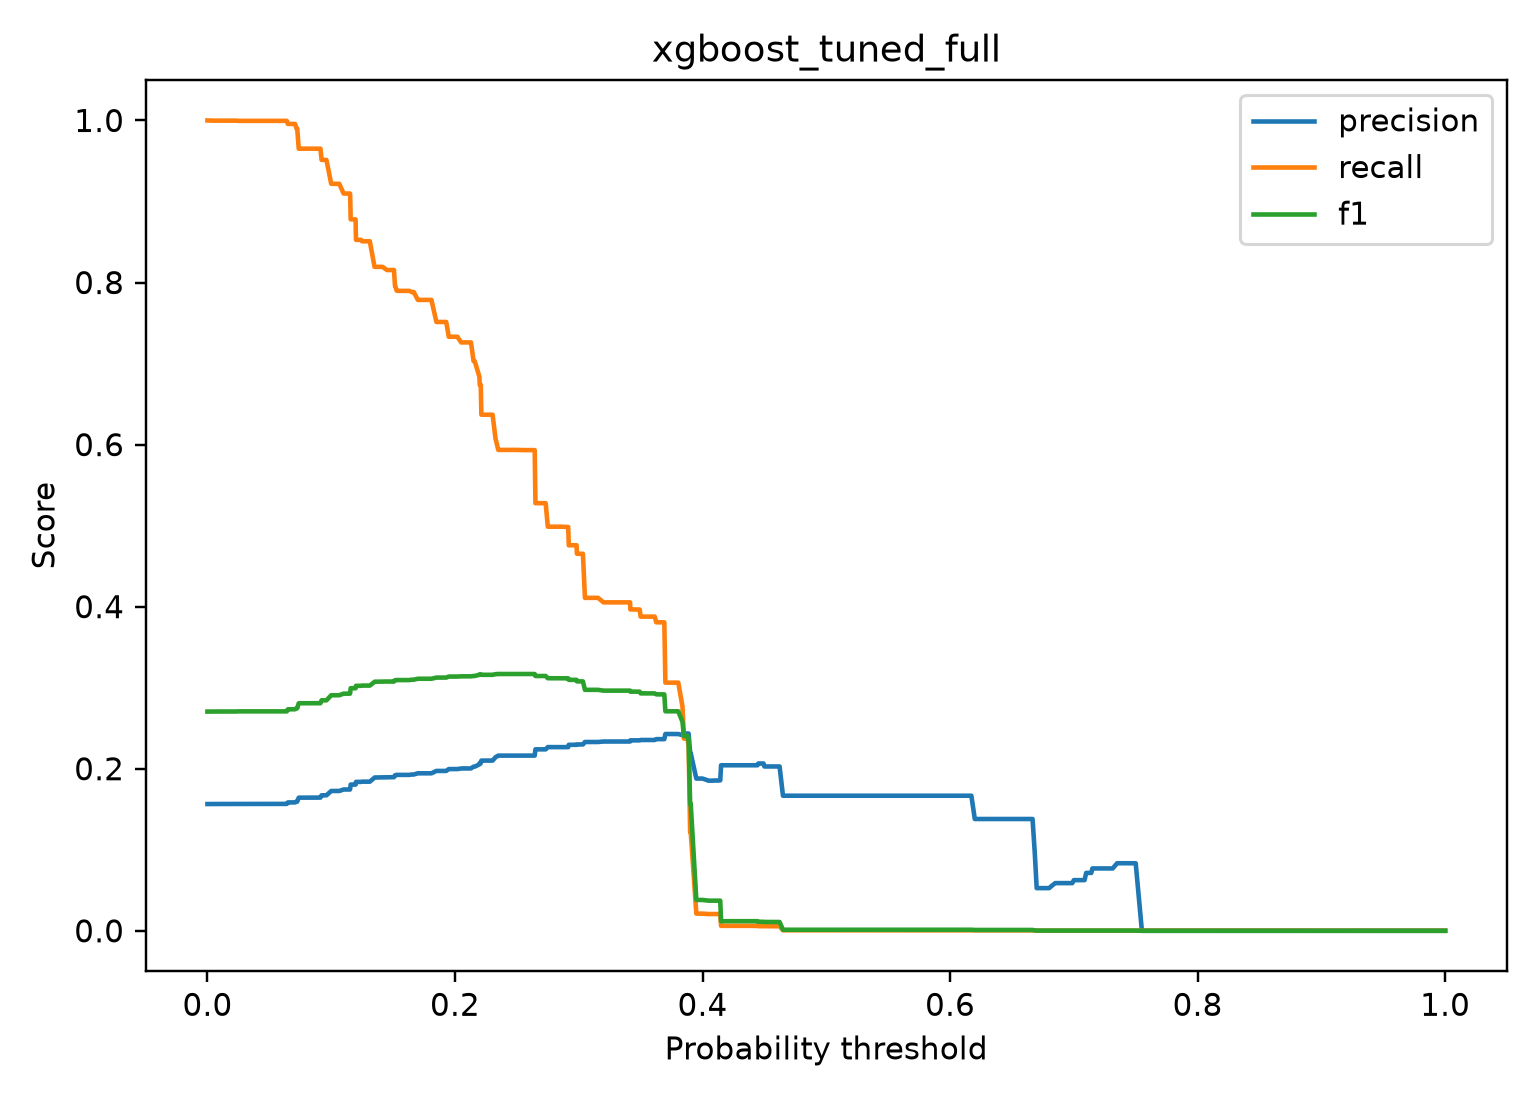

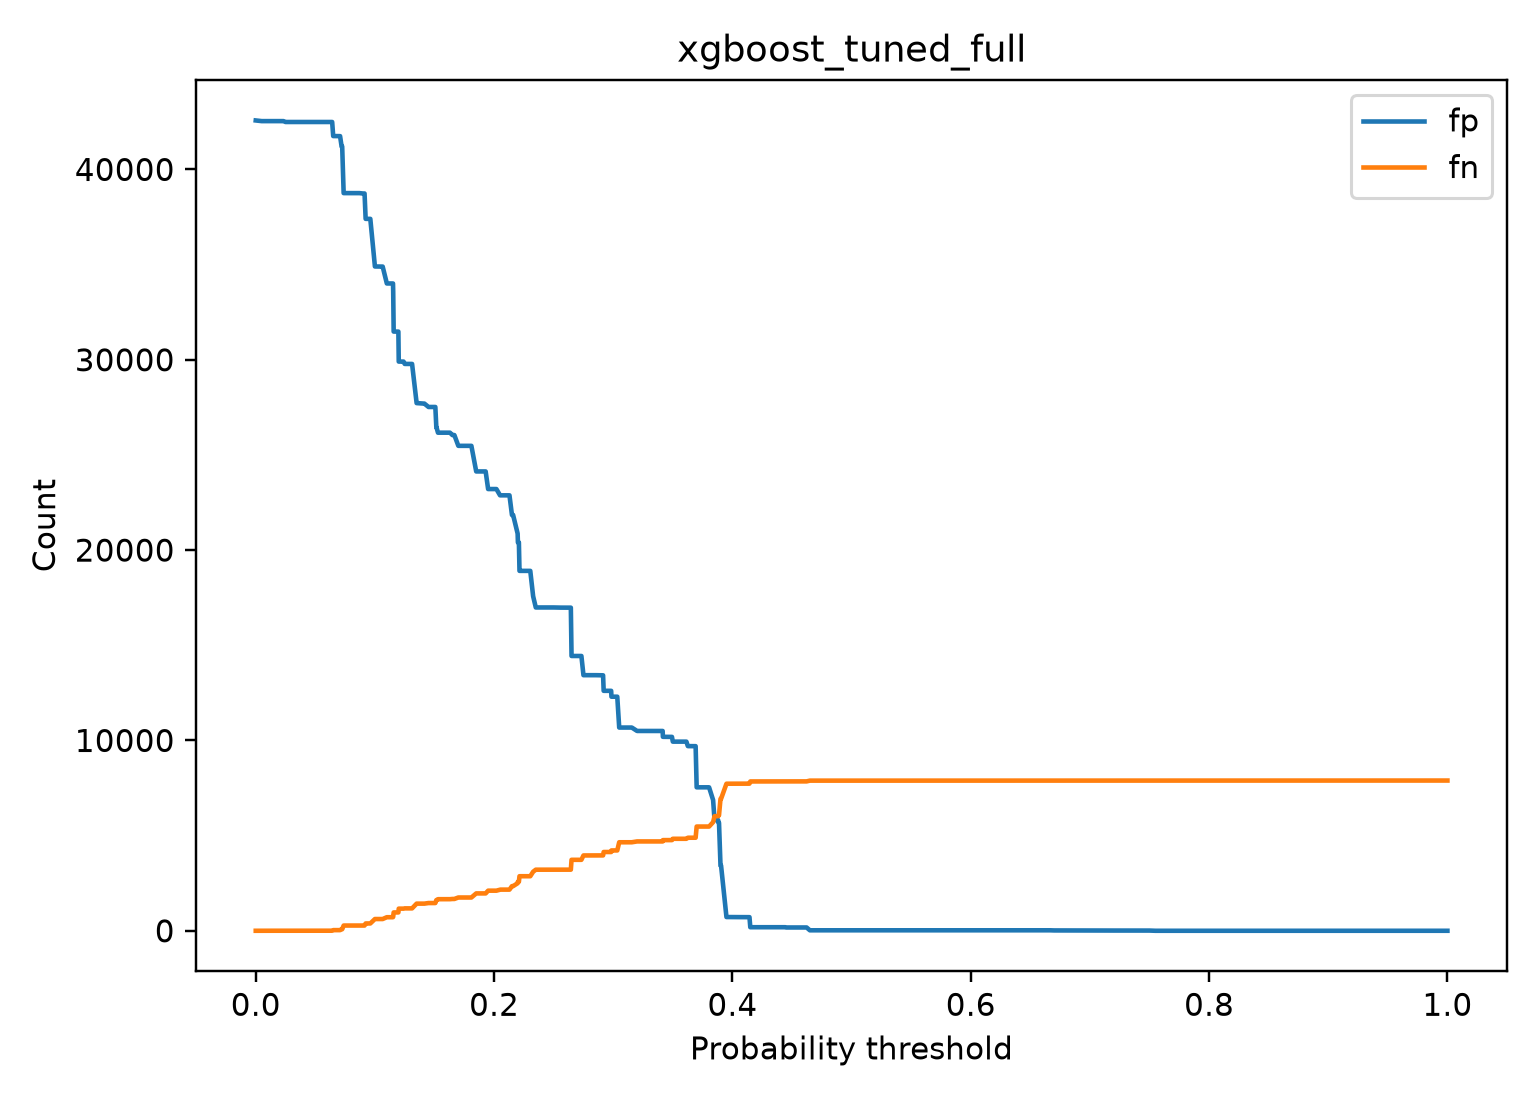

In [8]:
for name, choice in selection['models'].items():
    print(name)
    strategies=choice['strategies']
    display(pd.DataFrame({k:v for k,v in strategies.items() if k!='precision_sensitivity'}).T)
    display(pd.DataFrame(strategies['precision_sensitivity']).T)
    for plot in ['threshold_metrics','error_tradeoff']:
        display(Image(filename=str(OUT / 'figures/validation' / f'{name}_{plot}.png')))

## Paired uncertainty
Calendar-date block percentile bootstrap, XGBoost minus balanced LR, fixed seed. Days are assumed exchangeable; serial dependence across dates and model-selection uncertainty are not captured.

In [9]:
display(canonical['selection']['uncertainty'])

{'method': 'paired calendar-date block percentile bootstrap; assumes exchangeable dates',
 'seed': 42,
 'requested_resamples': 300,
 'valid_resamples': 300,
 'confidence': 0.95,
 'source': 'Recomputed with the repository paired_bootstrap implementation from the saved, ID-aligned validation prediction CSVs; no test data was read.',
 'xgboost_minus_logistic_intervals': {'average_precision': [-0.026506574858046878,
   0.010649818051998723],
  'roc_auc': [-0.02517415237974428, 0.010877692788638597],
  'f1': [-0.02228018322792042, 0.009168329273295035]}}

## Frozen held-out test evaluation
The tracked canonical manifest is the source for the test metrics in this checkout because the ignored `reports/evaluation/test_metrics.json` and saved test predictions are absent. The calendar test period appeared in an earlier pre-congestion experiment and was reproduced during audit; it was not used for selection in the frozen run, but was not untouched throughout project history. No test curves are available to display here.

In [10]:
test_window = canonical['windows']['test']
test_rows = {}
for name, model in canonical['selection']['models'].items():
    metrics = model['test']
    test_rows[name] = {
        'n': test_window['rows'],
        'prevalence': test_window['prevalence'],
        **{key: value for key, value in metrics.items() if key != 'confusion_matrix'},
        **metrics['confusion_matrix'],
    }
display(pd.DataFrame(test_rows).T[['n','prevalence','precision','recall','f1','roc_auc','average_precision','brier','log_loss','tn','fp','fn','tp']])
print(canonical['provenance']['test_period_reuse'])

,n,prevalence,precision,recall,f1,roc_auc,average_precision,brier,log_loss,tn,fp,fn,tp
logistic_balanced,48581.0,0.268562,0.296195,0.488005,0.368642,0.543888,0.294262,0.198391,0.586488,20405.0,15129.0,6680.0,6367.0
xgboost_tuned_full,48581.0,0.268562,0.334651,0.531923,0.410833,0.598862,0.337091,0.195484,0.586880,21736.0,13798.0,6107.0,6940.0


The same calendar test period was used in an earlier pre-congestion experiment and reproduced during audit. It was not used to select models or thresholds for this frozen run; it was not untouched throughout project history.


## Limitations and conclusions
Historical features use earlier calendar-date outcomes; exact availability at the scheduled prediction time remains unverified, so availability-time leakage is possible. Class imbalance, temporal shift, one historical dataset, calibration sample size and unspecified intervention costs limit generalization. Calibration is evaluated conditional on already-selected hyperparameters, which were originally tuned using the whole original training period; the calibration block is outside estimator fitting but not independent of historical hyperparameter selection. Do not claim fully nested model selection or production readiness.

## Reproduce
From the repository root, after `python -m pip install -e .`:
```bash
python -m pytest -q
python scripts/compare_models.py --n-jobs 4
python -m flight_delay.evaluation.evaluate validation --output-dir reports/evaluation --n-jobs 4 --bootstrap 300
python -m flight_delay.evaluation.evaluate final-test --output-dir reports/evaluation
```
Use a new output directory for a new experiment. Frozen selections and completed test reports are protected against accidental overwrites. On macOS install OpenMP (`brew install libomp`) before importing XGBoost. See the report for the local runtime workaround.